# Proceso de Selección de Variables

## Librerías y Configuración

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", "{:.3f}".format)
sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (12, 6)


In [2]:
df = pd.read_csv("../data/df_final.csv")

TARGET = "in_hospital_mortality"

numeric_cols = df.select_dtypes(include=["int64", "float64", "int32"]).columns.tolist()
numeric_cols = [c for c in numeric_cols if c != TARGET]

cat_cols = df.select_dtypes(include=["object", "category"]).columns.tolist()

C:\Users\Yepes Zuleta\AppData\Local\Temp\ipykernel_35964\4033841131.py:8: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_cols = df.select_dtypes(include=["object", "category"]).columns.tolist()


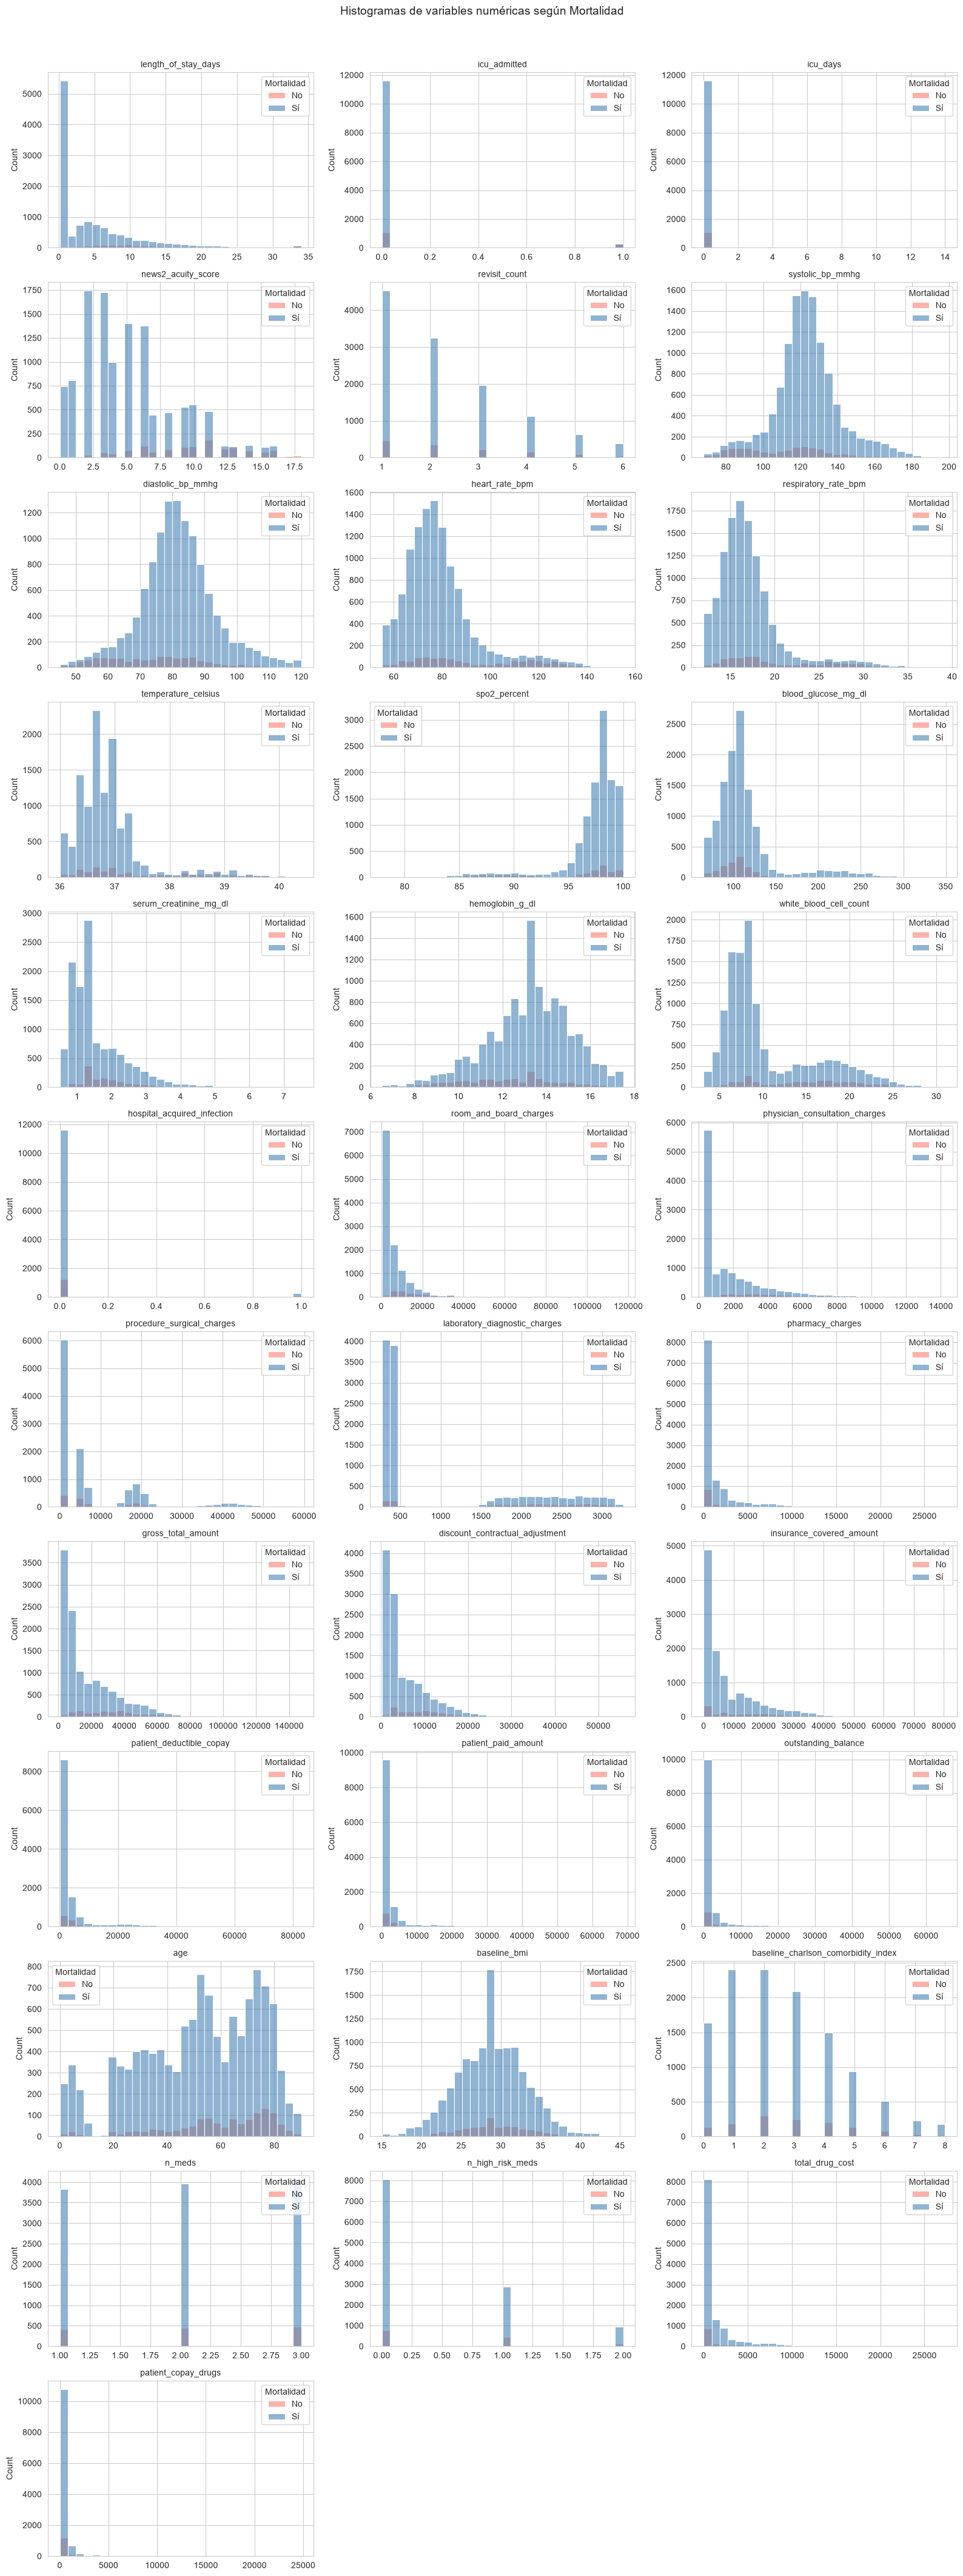

In [4]:
n_cols = 3
n_rows = int(np.ceil(len(numeric_cols) / n_cols))

fig, axes = plt.subplots(n_rows, n_cols, figsize=(16, n_rows * 3.5))
axes = axes.flatten()

for i, col in enumerate(numeric_cols):
    sns.histplot(data=df, x=col, hue=TARGET, bins=30, 
                 palette={0: "steelblue", 1: "salmon"},
                 alpha=0.6, ax=axes[i], kde=False)
    axes[i].set_title(col, fontsize=10)
    axes[i].set_xlabel("")
    axes[i].legend(title="Mortalidad", labels=["No", "Sí"])

for j in range(i + 1, len(axes)):
    axes[j].set_visible(False)

plt.suptitle("Histogramas de variables numéricas según Mortalidad", fontsize=14, y=1.01)
plt.tight_layout()
plt.show()

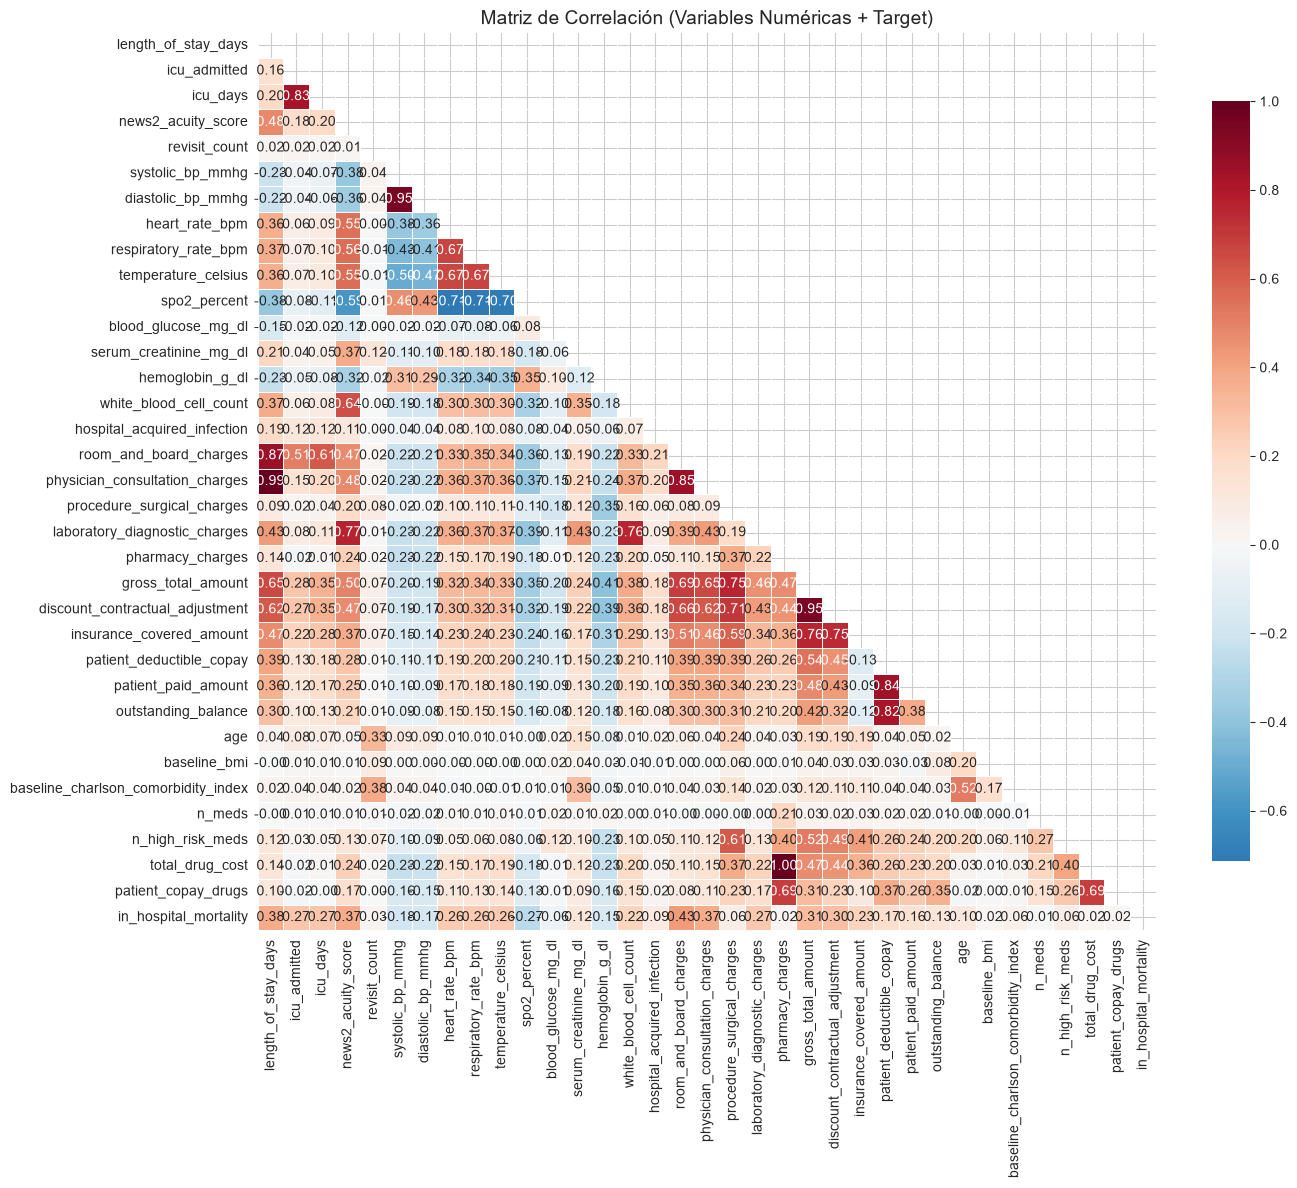

In [ ]:
corr = df[numeric_cols + [TARGET]].corr()

plt.figure(figsize=(14, 12))
mask = np.triu(np.ones_like(corr, dtype=bool))  
sns.heatmap(corr, mask=mask, annot=True, fmt=".2f", cmap="RdBu_r",
            center=0, square=True, linewidths=0.5,
            cbar_kws={"shrink": 0.8})
plt.title("Matriz de Correlación (Variables Numéricas + Target)", fontsize=14)
plt.tight_layout()
plt.show()

room_and_board_charges                 0.425
length_of_stay_days                    0.376
news2_acuity_score                     0.373
physician_consultation_charges         0.368
gross_total_amount                     0.314
discount_contractual_adjustment        0.298
icu_admitted                           0.273
icu_days                               0.271
spo2_percent                          -0.268
laboratory_diagnostic_charges          0.266
heart_rate_bpm                         0.263
respiratory_rate_bpm                   0.261
temperature_celsius                    0.258
insurance_covered_amount               0.234
white_blood_cell_count                 0.220
systolic_bp_mmhg                      -0.181
diastolic_bp_mmhg                     -0.175
patient_deductible_copay               0.175
patient_paid_amount                    0.155
hemoglobin_g_dl                       -0.155
outstanding_balance                    0.134
serum_creatinine_mg_dl                 0.121
age       

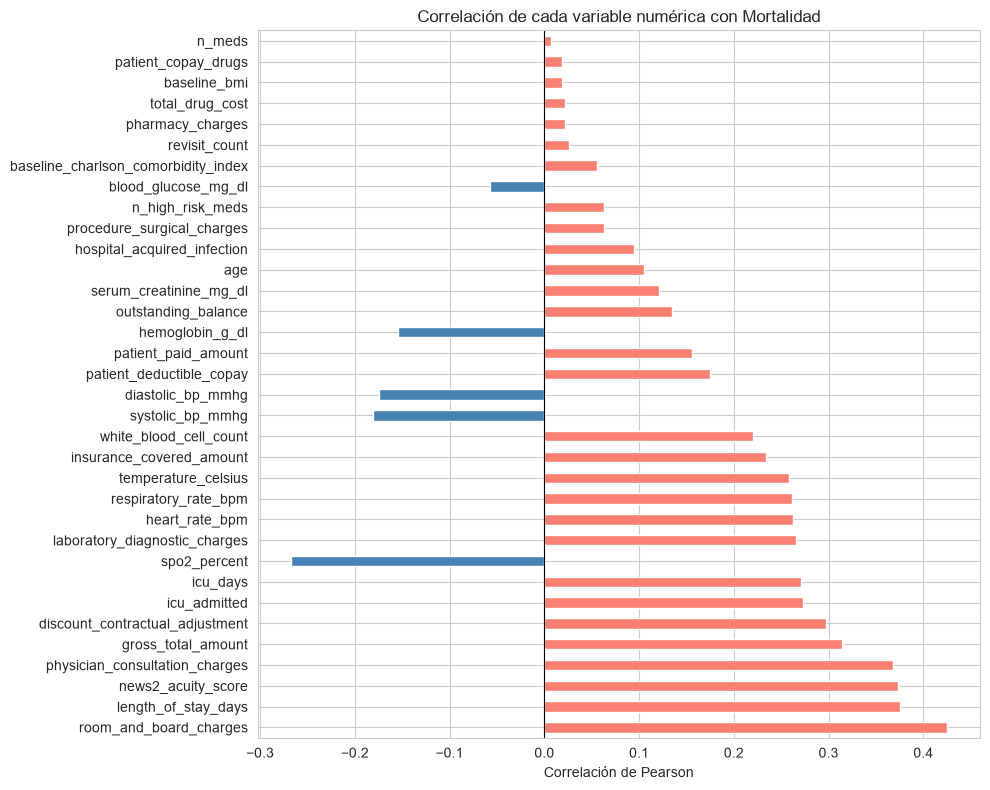

In [ ]:
target_corr = corr[TARGET].drop(TARGET).sort_values(key=abs, ascending=False)
print(target_corr)

plt.figure(figsize=(10, 8))
colors = ["salmon" if v > 0 else "steelblue" for v in target_corr]
target_corr.plot(kind="barh", color=colors)
plt.axvline(0, color="black", linewidth=0.8)
plt.title("Correlación de cada variable numérica con Mortalidad")
plt.xlabel("Correlación")
plt.tight_layout()
plt.show()


--- encounter_type ---
in_hospital_mortality       0      1
encounter_type                      
Emergency             100.000  0.000
Inpatient              72.600 27.400
Outpatient            100.000  0.000


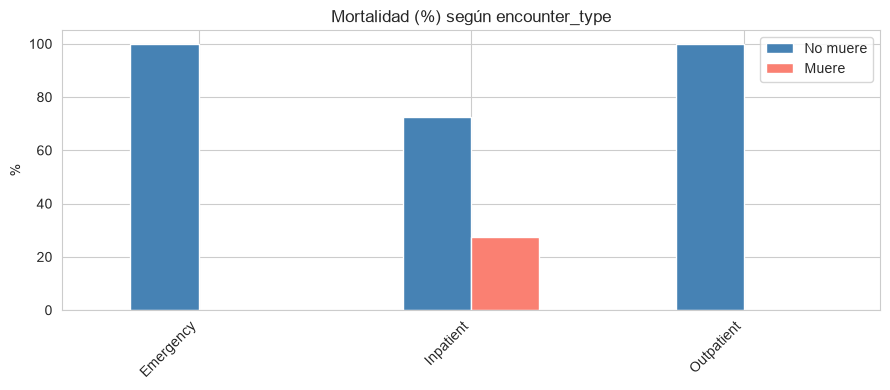


--- admission_urgency ---
in_hospital_mortality      0      1
admission_urgency                  
Elective              92.600  7.400
Emergency             91.800  8.200
Urgent                80.100 19.900


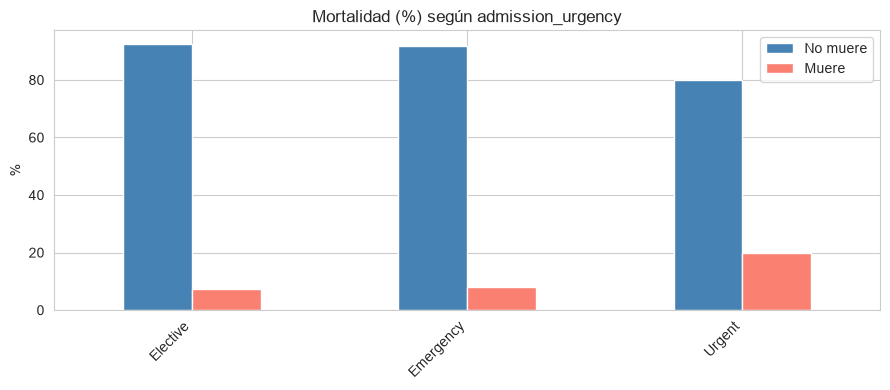


--- department ---
in_hospital_mortality      0      1
department                         
Cardiology            86.100 13.900
General Medicine      93.400  6.600
General Surgery       94.600  5.400
ICU                   75.700 24.300
Obstetrics            99.300  0.700
Oncology              89.500 10.500
Orthopedics           87.800 12.200
Pediatrics            94.800  5.200


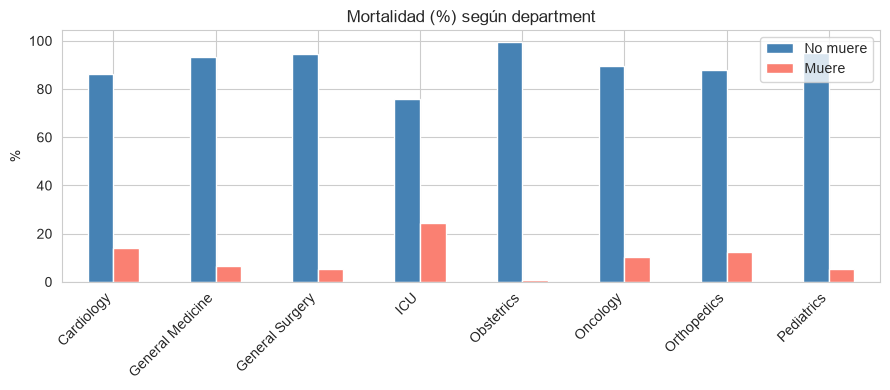


--- disease_category ---
in_hospital_mortality      0      1
disease_category                   
Cardiovascular        86.100 13.900
Endocrine             96.200  3.800
Gastrointestinal      94.600  5.400
Infectious            77.900 22.100
Musculoskeletal       95.700  4.300
Obstetrics            99.300  0.700
Oncology              89.500 10.500
Pediatrics            99.000  1.000
Renal                 94.700  5.300
Respiratory           91.700  8.300
Trauma                77.400 22.600


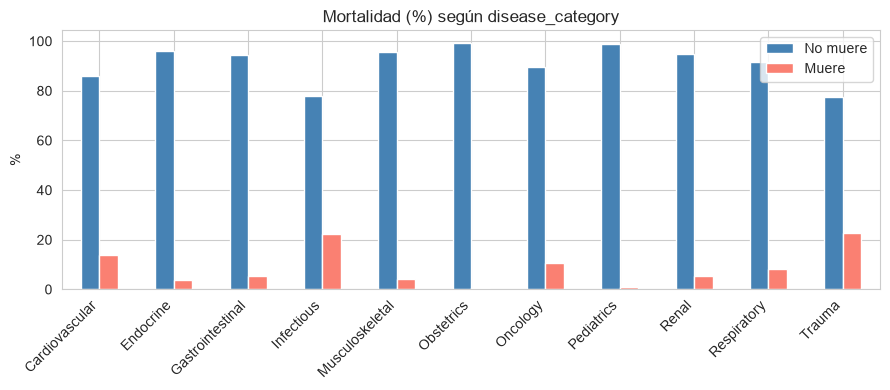


--- disease_severity ---
in_hospital_mortality      0      1
disease_severity                   
Critical              63.000 37.000
Mild                  98.600  1.400
Moderate              94.900  5.100
Severe                86.000 14.000


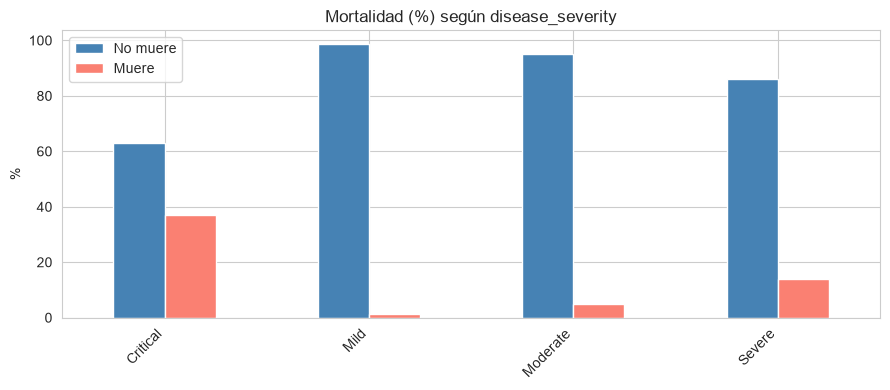


--- procedure_complexity ---
in_hospital_mortality      0      1
procedure_complexity               
High-Complexity       89.500 10.500
Major                 85.700 14.300
Minor                 86.800 13.200
Moderate              86.500 13.500
Unknown               94.300  5.700


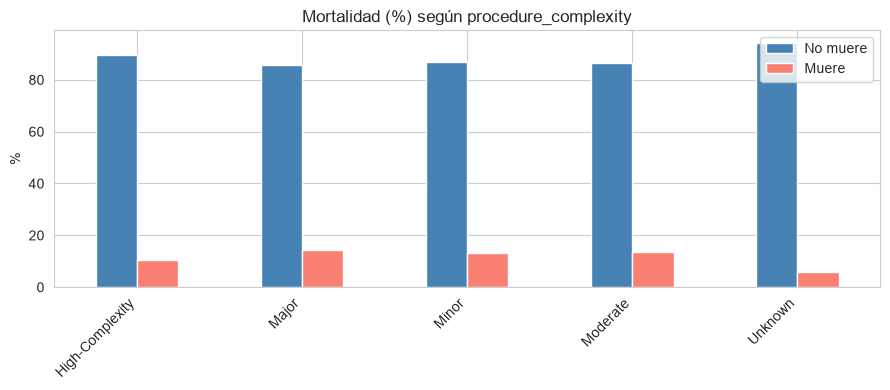


--- payment_status ---
in_hospital_mortality      0      1
payment_status                     
Paid in Full          96.400  3.600
Partial Payment       89.800 10.200


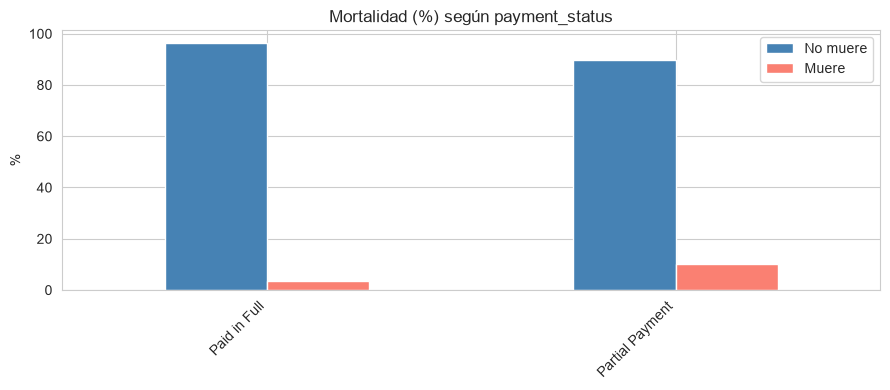


--- claim_status ---
in_hospital_mortality          0      1
claim_status                           
Approved                  90.400  9.600
Rejected                  85.600 14.400
Self-Pay / Not Applicable 91.700  8.300


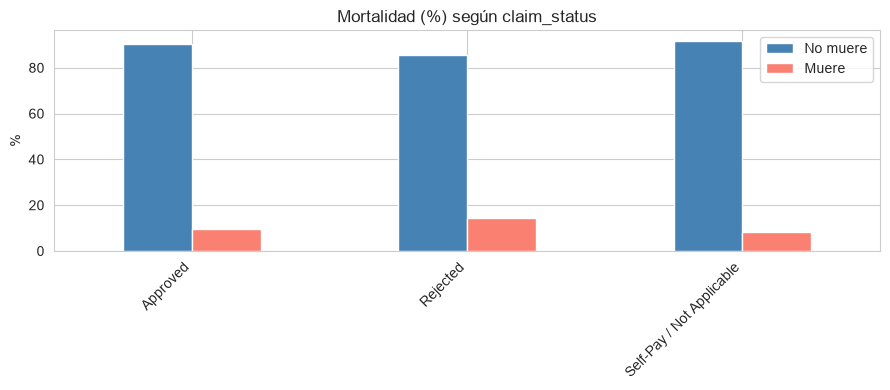


--- gender ---
in_hospital_mortality      0      1
gender                             
Female                90.100  9.900
Male                  89.700 10.300


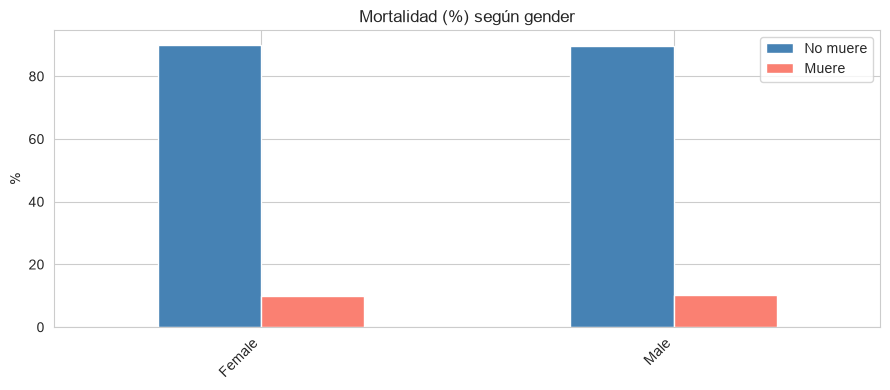


--- blood_group ---
in_hospital_mortality      0      1
blood_group                        
A+                    90.300  9.700
A-                    90.300  9.700
AB+                   91.200  8.800
AB-                   91.200  8.800
B+                    90.700  9.300
B-                    87.300 12.700
O+                    89.200 10.800
O-                    90.200  9.800


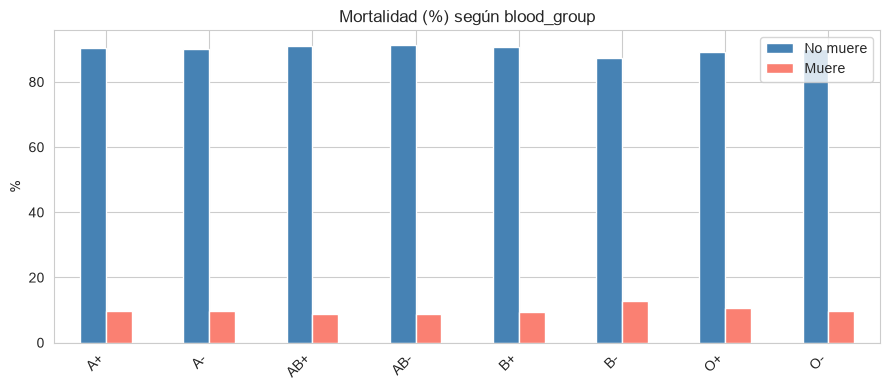


--- marital_status ---
in_hospital_mortality      0      1
marital_status                     
Divorced              89.500 10.500
Married               89.500 10.500
Single                92.800  7.200
Widowed               85.800 14.200


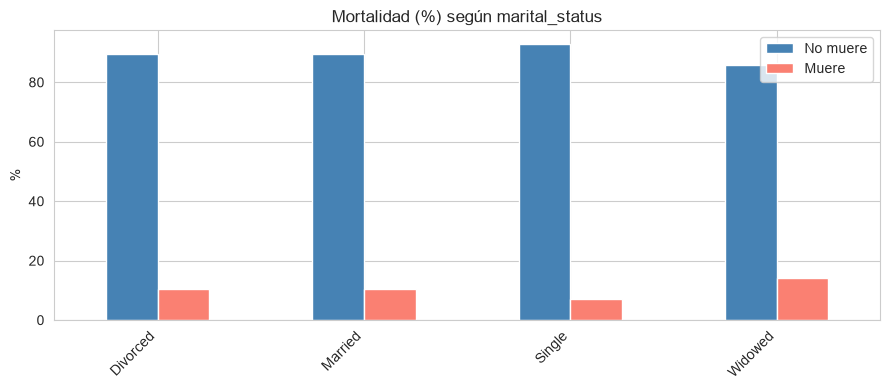


--- race_ethnicity ---
in_hospital_mortality      0      1
race_ethnicity                     
African American      89.900 10.100
Asian                 90.800  9.200
Caucasian             90.000 10.000
Hispanic              89.000 11.000
Other                 90.300  9.700


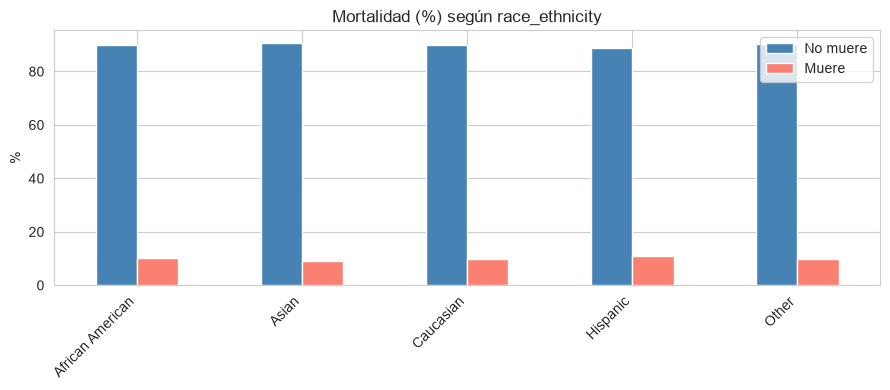


--- residential_zone ---
in_hospital_mortality      0      1
residential_zone                   
Rural                 88.300 11.700
Suburban              90.200  9.800
Urban                 90.100  9.900


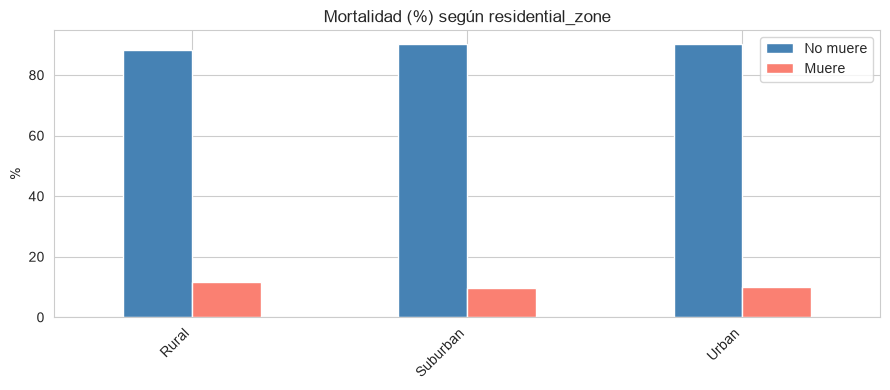


--- socioeconomic_tier ---
in_hospital_mortality      0      1
socioeconomic_tier                 
High                  90.400  9.600
Low                   89.100 10.900
Middle                90.200  9.800


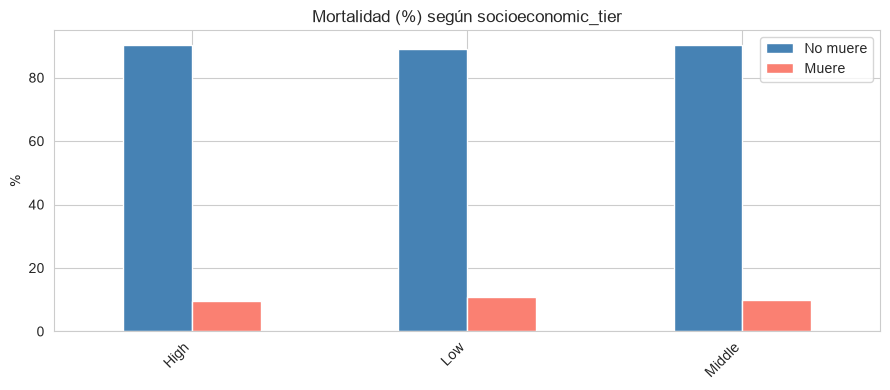


--- primary_insurance_provider ---
in_hospital_mortality           0      1
primary_insurance_provider              
BlueCross                  91.200  8.800
Kaiser                     92.300  7.700
Medicaid                   90.800  9.200
Medicare                   86.600 13.400
Self-Pay                   91.700  8.300
UnitedHealth               91.900  8.100


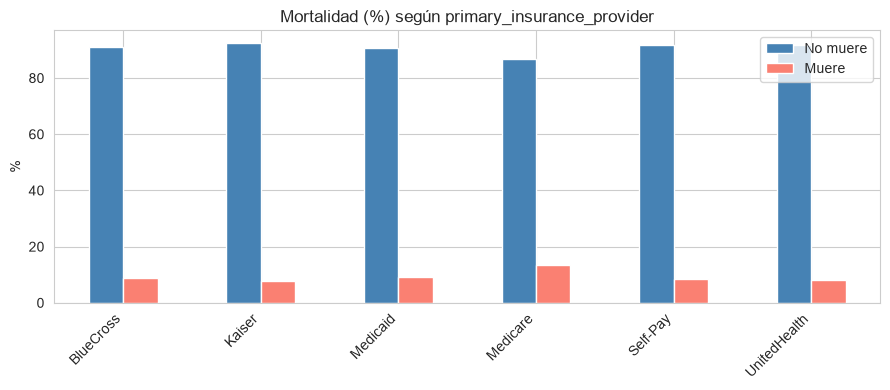


--- smoker_status ---
in_hospital_mortality      0      1
smoker_status                      
Current               89.300 10.700
Former                89.500 10.500
Never                 90.300  9.700
Unknown               89.500 10.500


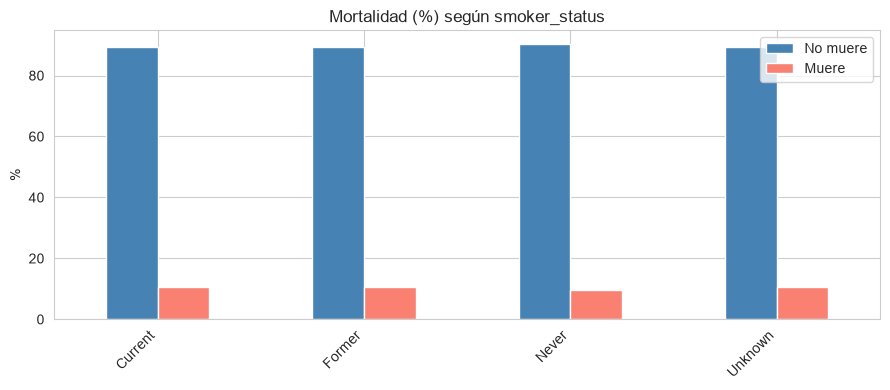

In [7]:
for col in cat_cols:
    print(f"\n--- {col} ---")
    ct = pd.crosstab(df[col], df[TARGET], normalize="index") * 100
    print(ct.round(1))
    
    # Gráfico
    fig, ax = plt.subplots(figsize=(9, 4))
    ct.plot(kind="bar", stacked=False, color=["steelblue", "salmon"], ax=ax)
    ax.set_title(f"Mortalidad (%) según {col}")
    ax.set_ylabel("%")
    ax.set_xlabel("")
    ax.legend(["No muere", "Muere"])
    plt.xticks(rotation=45, ha="right")
    plt.tight_layout()
    plt.show()

## Selección Final de Variables para el Modelo de Mortalidad Hospitalaria

Despues del análisis exploratorio de las variables se seleccionaron las siguientes de acuerdo a su correlación y distribución con la variable objetivo:

numeric_features = [
    "age", "baseline_bmi", "baseline_charlson_comorbidity_index",
    "systolic_bp_mmhg", "diastolic_bp_mmhg", "heart_rate_bpm",
    "respiratory_rate_bpm", "temperature_celsius", "spo2_percent",
    "blood_glucose_mg_dl", "serum_creatinine_mg_dl", "hemoglobin_g_dl",
    "white_blood_cell_count", "length_of_stay_days", "icu_days",
    "news2_acuity_score", "n_meds", "n_high_risk_meds", "total_drug_cost"
]

categoric_features = [
    "gender", "race_ethnicity", "socioeconomic_tier", "residential_zone",
    "smoker_status", "blood_group", "marital_status", "primary_insurance_provider",
    "encounter_type", "admission_urgency", "department",
    "disease_category", "disease_severity", "procedure_complexity"
]

### Criterios generales de selección

1. **Relevancia clínica**: Factores de riesgo
2. **Poder discriminativo**: Mostraban separación importante en los histogramas
3. **Disponibilidad temporal**: Variables en el ingreso o en la estancia de la hospitalización

Este conjunto de **33 variables** (19 numéricas + 14 categóricas)